# 02 Plate Solving

**Eingabe**: kalibriertes Referenzbild (erster Frame der Nacht, bestes Seeing)  
**Ausgabe**: FITS mit WCS-Header (RA/Dec ↔ Pixel)

Werkzeug: **ASTAP-CLI** (`astap -f <datei> -r 10 -wcs`)  
Binary auf macOS: `/Applications/ASTAP.app/Contents/MacOS/astap`  
Download + Datenbank (D05/D80): https://www.hnsky.org/astap.htm

> **Demo-Modus**: Die synthetischen Demo-FITS haben WCS bereits im Header.  
> ASTAP findet kein echtes Sternmuster → Schritt 3 schlägt fehl und fällt  
> automatisch auf den vorhandenen Header-WCS zurück.

## Schritt 1 — Pfade laden

Liest `session_config.json` aus Notebook 01, ermittelt den Pfad zu den kalibrierten Frames
und wählt das erste Frame als Referenzbild für das Plate Solving.

In [1]:
import subprocess, json
from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS

# ASTAP-Binary auf macOS (liegt im .app-Bundle)
ASTAP = "/Applications/ASTAP.app/Contents/MacOS/astap"

# session_config.json aus Notebook 01 laden
_cfgs = list(Path.home().rglob("session_config.json"))
if not _cfgs:
    raise FileNotFoundError("session_config.json nicht gefunden — bitte Notebook 01 ausführen.")
session_cfg = json.loads(_cfgs[0].read_text())
WORKSPACE = Path(session_cfg["workspace"])
DIR_CAL   = Path(session_cfg["dir_cal"])

_FITS_GLOB = ["*.fits", "*.fit", "*.fts", "*.FITS", "*.FIT", "*.FTS"]
cal_frames = sorted(f for g in _FITS_GLOB for f in DIR_CAL.glob(g))
if not cal_frames:
    raise FileNotFoundError(f"Keine FITS in {DIR_CAL} — Siril-Kalibrierung abgeschlossen?")
REF = cal_frames[0]

print(f"ASTAP:              {ASTAP}  ({'OK' if Path(ASTAP).exists() else 'NICHT GEFUNDEN'})")
print(f"Workspace:          {WORKSPACE}")
print(f"Kalibrierte Bilder: {len(cal_frames)} in {DIR_CAL}")
print(f"Referenzbild:       {REF}")

ASTAP:              /Applications/ASTAP.app/Contents/MacOS/astap  (OK)
Workspace:          /Users/apos/Nextcloud/WORKSPACE/ASTRO/PHOTOMETRIE_PY/demo/siril_workspace
Kalibrierte Bilder: 20 in /Users/apos/Nextcloud/WORKSPACE/ASTRO/PHOTOMETRIE_PY/demo/siril_workspace/process
Referenzbild:       /Users/apos/Nextcloud/WORKSPACE/ASTRO/PHOTOMETRIE_PY/demo/siril_workspace/process/pp_light_001.fits


## Schritt 2 — Referenzbild anzeigen

Zeigt das kalibrierte Referenzbild mit logarithmischer Streckung (Percentile 1–99.5 %).
So werden sowohl schwache Hintergrundsterne als auch helle Objekte sichtbar.

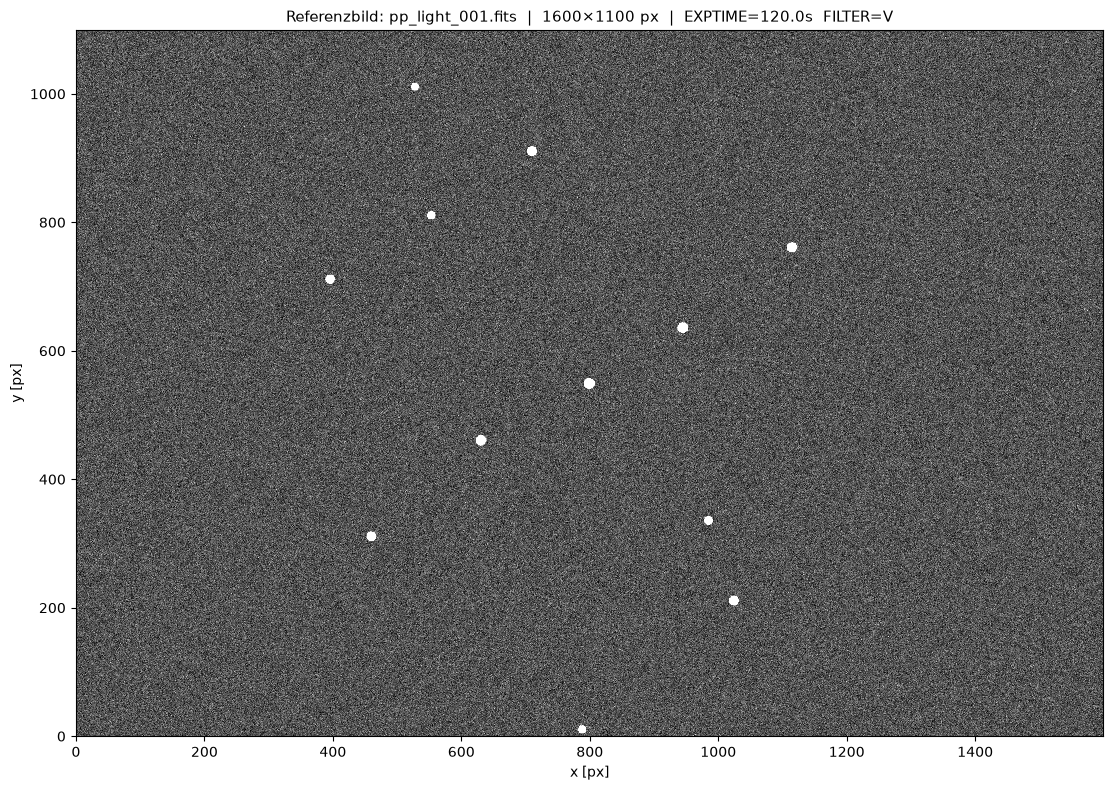

Pixelbereich: 8 – 65535 ADU  |  ZScale: 19 – 111


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import ZScaleInterval

with fits.open(REF) as hdul:
    img_data = hdul[0].data.astype(float)
    hdr = hdul[0].header

interval = ZScaleInterval()
vmin, vmax = interval.get_limits(img_data)

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img_data, origin="lower", cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
ax.set_title(f"Referenzbild: {REF.name}  |  {img_data.shape[1]}×{img_data.shape[0]} px  |  "
             f"EXPTIME={hdr.get('EXPTIME','?')}s  FILTER={hdr.get('FILTER','?')}", fontsize=11)
ax.set_xlabel("x [px]")
ax.set_ylabel("y [px]")
plt.tight_layout()
plt.show()
print(f"Pixelbereich: {img_data.min():.0f} – {img_data.max():.0f} ADU  |  ZScale: {vmin:.0f} – {vmax:.0f}")

## Schritt 3 — Plate Solving mit ASTAP

ASTAP vergleicht die Sternpositionen im Bild mit einer lokalen Sternkatalog-Datenbank
(D05 für schwache Felder, D80 für helle Felder wie Delta Cep) und schreibt den
gefundenen WCS zurück in den FITS-Header.

**Demo-Modus**: Synthetische Bilder haben kein echtes Sternmuster → ASTAP schlägt fehl.
Die Zelle fällt in diesem Fall automatisch auf den vorhandenen Header-WCS zurück.

In [3]:
if not Path(ASTAP).exists():
    print(f"⚠  ASTAP nicht gefunden: {ASTAP}")
    print("   Download: https://www.hnsky.org/astap.htm")
    print("   → Fallback: vorhandenen WCS aus FITS-Header verwenden")
    WCS_SOURCE = "header (kein ASTAP)"
else:
    result = subprocess.run(
        [ASTAP, "-f", str(REF), "-r", "10", "-wcs"],
        capture_output=True, text=True
    )
    output = (result.stdout + result.stderr).strip()
    print(output[-800:] if output else "(keine Ausgabe)")

    if result.returncode == 0 and "No solution" not in output:
        print("✓ Plate solving erfolgreich — WCS in FITS-Header geschrieben.")
        WCS_SOURCE = "ASTAP"
    else:
        print("\n⚠  ASTAP: keine Lösung gefunden.")
        print("   Mögliche Ursachen: fehlende Datenbank, synthetische Demo-Daten,")
        print("   zu kleines Suchfenster (-r) oder falsches Bildfeld.")
        print("   → Fallback: vorhandenen WCS aus FITS-Header verwenden")
        WCS_SOURCE = "header (ASTAP fehlgeschlagen)"

print(f"\nWCS-Quelle: {WCS_SOURCE}")

Using star database D80
/Users/apos/Nextcloud/WORKSPACE/ASTRO/PHOTOMETRIE_PY/demo/siril_workspace/process/pp_light_001.fits, will use mean value 78 as background rather then most common value 49
11 stars, 70 quads selected in the image. 32 database stars, 204 database quads required for the 0.88° square search window. Step size 0.44°. Oversize 2.00
No solution found!  :(

⚠  ASTAP: keine Lösung gefunden.
   Mögliche Ursachen: fehlende Datenbank, synthetische Demo-Daten,
   zu kleines Suchfenster (-r) oder falsches Bildfeld.
   → Fallback: vorhandenen WCS aus FITS-Header verwenden

WCS-Quelle: header (ASTAP fehlgeschlagen)


## Schritt 4 — WCS prüfen und visualisieren

Zeigt eine **HTML-Tabelle** mit den wichtigsten WCS-Kennzahlen, danach das Referenzbild
mit **RA/Dec-Koordinatengitter** (cyan). Zwei Markierungen:

- **Grau `+`** = Sensorzentrum (geometrische Mitte des Chips)
- **Gelber Kreis `○`** = Zielstern-Position aus FITS-Header (`OBJECT` + `CRVAL`) — ungefähre Lage, exakte Koordinaten folgen in Notebook 03 via SIMBAD

In [ ]:
import astropy.units as u
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.visualization import ZScaleInterval
from IPython.display import display, HTML

with fits.open(REF) as hdul:
    w = WCS(hdul[0].header)
    img_data_wcs = hdul[0].data.astype(float)
    hdr = hdul[0].header
    ny, nx = img_data_wcs.shape

# --- WCS-Kennzahlen ---
cx, cy = nx / 2, ny / 2
center_ra, center_dec = w.all_pix2world([[cx, cy]], 0)[0]
ps  = w.proj_plane_pixel_scales()
scale_as = float(ps[0].to(u.arcsec).value)
fov_ra   = nx * scale_as / 60
fov_dec  = ny * scale_as / 60
pc       = w.wcs.get_pc()
rot_deg  = np.degrees(np.arctan2(pc[0, 1], pc[0, 0]))
center_coord = SkyCoord(ra=center_ra*u.deg, dec=center_dec*u.deg)
center_hms   = center_coord.to_string("hmsdms", sep=":")

obj_name = hdr.get("OBJECT", "unbekannt")
tgt_ra   = hdr.get("CRVAL1", None)
tgt_dec  = hdr.get("CRVAL2", None)
tgt_px, tgt_py = w.all_world2pix([[tgt_ra, tgt_dec]], 0)[0] if tgt_ra else (cx, cy)

# --- HTML-Tabelle ---
src_color = "#4caf50" if WCS_SOURCE == "ASTAP" else "#ff9800"
display(HTML(f"""
<table style="border-collapse:collapse;font-family:monospace;font-size:13px;margin:8px 0">
  <tr style="background:#1e1e2e;color:#cdd6f4">
    <th colspan="2" style="padding:6px 16px;text-align:center;letter-spacing:1px">
      WCS — Plate-Solve-Ergebnis</th></tr>
  <tr><td style="padding:4px 12px;color:#888">Quelle</td>
      <td style="padding:4px 12px;color:{src_color}"><b>{WCS_SOURCE}</b></td></tr>
  <tr style="background:#11111b"><td style="padding:4px 12px;color:#888">Sensorzentrum</td>
      <td style="padding:4px 12px">RA {center_ra:.4f}°  Dec {center_dec:+.4f}°
        <span style="color:#888">({center_hms})</span></td></tr>
  <tr><td style="padding:4px 12px;color:#888">Zielstern</td>
      <td style="padding:4px 12px"><b>{obj_name}</b>
        — exakte Koordinaten folgen in NB03 (SIMBAD)</td></tr>
  <tr style="background:#11111b"><td style="padding:4px 12px;color:#888">Pixelskala</td>
      <td style="padding:4px 12px">{scale_as:.3f} arcsec/px</td></tr>
  <tr><td style="padding:4px 12px;color:#888">Bildfeld</td>
      <td style="padding:4px 12px">{fov_ra:.1f}′ × {fov_dec:.1f}′</td></tr>
  <tr style="background:#11111b"><td style="padding:4px 12px;color:#888">Rotation</td>
      <td style="padding:4px 12px">{rot_deg:.2f}°</td></tr>
  <tr><td style="padding:4px 12px;color:#888">Bildgröße</td>
      <td style="padding:4px 12px">{nx} × {ny} px</td></tr>
</table>"""))

# --- WCS-Plot mit Koordinatengitter ---
interval = ZScaleInterval()
vmin, vmax = interval.get_limits(img_data_wcs)

fig = plt.figure(figsize=(12, 8.5))
# Platz oben für RA-Achse (WCSAxes), unten für Dec-Achse → kein ax.set_title()
ax = fig.add_subplot(1, 1, 1, projection=w)
fig.subplots_adjust(top=0.88)   # Freiraum oben für RA-Label

ax.imshow(img_data_wcs, origin="lower", cmap="gray",
          vmin=vmin, vmax=vmax, interpolation="nearest", aspect="equal")

# RA/Dec-Gitternetz
overlay = ax.get_coords_overlay("icrs")
overlay.grid(color="cyan", linestyle="--", linewidth=0.6, alpha=0.7)
overlay[0].set_axislabel("RA (J2000)", fontsize=10, minpad=0.5)
overlay[1].set_axislabel("Dec (J2000)", fontsize=10)
overlay[0].set_ticks(number=6)
overlay[1].set_ticks(number=5)
overlay[0].set_ticklabel(size=9)
overlay[1].set_ticklabel(size=9)

tr = ax.get_transform("pixel")

# Sensorzentrum: graues Kreuz
ax.plot(cx, cy, "+", color="#aaaaaa", markersize=12, markeredgewidth=1.2,
        transform=tr, label="Sensorzentrum")

# Zielstern: gelber Kreis + Beschriftung
ax.plot(tgt_px, tgt_py, "o", color="yellow", markersize=22,
        markeredgewidth=1.5, markerfacecolor="none",
        transform=tr, label=f"Zielstern: {obj_name}")
ax.annotate(obj_name, xy=(tgt_px, tgt_py),
            xytext=(tgt_px + 35, tgt_py + 35),
            xycoords=tr, textcoords=tr,
            color="yellow", fontsize=9, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color="yellow", lw=0.8))

# Titel als Text-Box INNERHALB des Bildes (oben links) → kein Konflikt mit WCS-Achsen
info = (f"{obj_name}  |  {REF.name}\n"
        f"{fov_ra:.1f}′ × {fov_dec:.1f}′  |  {scale_as:.2f}″/px  |  WCS: {WCS_SOURCE}")
ax.text(0.01, 0.98, info, transform=ax.transAxes,
        fontsize=8.5, color="white", va="top", ha="left",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.55))

ax.set_xlabel("x [px]", fontsize=10)
ax.set_ylabel("y [px]", fontsize=10)
ax.legend(loc="lower right", fontsize=9, framealpha=0.7)
plt.show()

## Schritt 5 — Sternbild-Kontext

Das Bildfeld (typisch 20′–60′) ist für sichtbare Sternbildlinien zu klein. Diese Zelle zeigt
deshalb eine **generische Übersichtskarte ~25° × 25°** um den Zielstern:

- Alle 88 IAU-Sternbilder mit Standard-Verbindungslinien (Quelle: `data/constellation_lines.json`)
- Beim ersten Aufruf werden die Sternpositionen via SIMBAD abgefragt und gecacht (~1–3 Min)
- Folgeaufrufe lesen nur den Cache — kein Netz nötig
- Automatische Auswahl der sichtbaren Sternbilder nach Abstand zum Zielstern
- Rotes FOV-Rechteck zeigt den tatsächlichen Bildausschnitt

In [ ]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# ---------------------------------------------------------------------------
# constellation_lines.json laden; bei erstem Aufruf auto-generieren
# ---------------------------------------------------------------------------
_ROOT   = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
_LINES  = _ROOT / "data" / "constellation_lines.json"
_SCRIPT = _ROOT / "tools" / "make_const_data.py"

if not _LINES.exists():
    print("⏳ Erst-Setup: Sternpositionen via SIMBAD abfragen (~1–3 Min) …")
    result = subprocess.run(
        [sys.executable, str(_SCRIPT)],
        capture_output=False, cwd=str(_ROOT)
    )
    if result.returncode != 0 or not _LINES.exists():
        raise RuntimeError(
            f"make_const_data.py fehlgeschlagen. "
            f"Manuell ausführen: python {_SCRIPT.relative_to(_ROOT)}"
        )

const_data = json.loads(_LINES.read_text())

# ---------------------------------------------------------------------------
# Zielkoordinaten (aus Schritt 4)
# ---------------------------------------------------------------------------
RA0  = tgt_ra  if "tgt_ra"  in dir() and tgt_ra  else center_ra
DEC0 = tgt_dec if "tgt_dec" in dir() and tgt_dec else center_dec
HALF = 13.5    # halbe Kartenbreite in Grad (±13.5° → ~27° Ausschnitt)

# ---------------------------------------------------------------------------
# Gnomische Projektion (korrekt für Himmelskoordinaten)
# ---------------------------------------------------------------------------
def gnom(ra, dec, ra0, dec0):
    r0, d0 = np.radians(ra0), np.radians(dec0)
    r,  d  = np.radians(np.asarray(ra,  float)), np.radians(np.asarray(dec, float))
    dr = r - r0
    dr = (dr + np.pi) % (2 * np.pi) - np.pi
    cos_c = np.sin(d0) * np.sin(d) + np.cos(d0) * np.cos(d) * np.cos(dr)
    x = -np.degrees(np.cos(d) * np.sin(dr) / cos_c)
    y =  np.degrees((np.cos(d0) * np.sin(d) - np.sin(d0) * np.cos(d) * np.cos(dr)) / cos_c)
    return float(x), float(y)

# ---------------------------------------------------------------------------
# Sternbilder auswählen: Mittelstern muss innerhalb SEARCH_R° liegen
# ---------------------------------------------------------------------------
SEARCH_R = HALF * 1.3   # Sternbild einbeziehen wenn mind. 1 Stern in diesem Radius

# Feste Farbpalette: rotiert durch alle sichtbaren Sternbilder
_PALETTE = [
    "#64b5f6","#ffcc80","#ce93d8","#80cbc4","#ef9a9a",
    "#a5d6a7","#fff176","#80deea","#f48fb1","#b39ddb",
]

# ---------------------------------------------------------------------------
# Plot aufbauen
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 11), facecolor="#07070f")
ax.set_facecolor("#07070f")
ax.set_aspect("equal")
ax.set_xlim(-HALF, HALF)
ax.set_ylim(-HALF, HALF)

legend_items = []
color_idx    = 0
drawn        = 0

for abbrev, entry in const_data.items():
    stars  = entry["stars"]
    lines  = entry["lines"]
    cname  = entry["name"]
    if not stars:
        continue

    # Sternbild einbeziehen wenn mind. 1 Stern nahe genug
    close = False
    for sd in stars.values():
        dx, dy = gnom(sd["ra"], sd["dec"], RA0, DEC0)
        if abs(dx) <= SEARCH_R and abs(dy) <= SEARCH_R:
            close = True
            break
    if not close:
        continue

    col = _PALETTE[color_idx % len(_PALETTE)]
    color_idx += 1
    drawn     += 1

    # Linien zeichnen
    for s1, s2 in lines:
        if s1 not in stars or s2 not in stars:
            continue
        x1, y1 = gnom(stars[s1]["ra"], stars[s1]["dec"], RA0, DEC0)
        x2, y2 = gnom(stars[s2]["ra"], stars[s2]["dec"], RA0, DEC0)
        # Linie nur wenn beide Endpunkte grob im erweiterten Bereich liegen
        if max(abs(x1), abs(x2), abs(y1), abs(y2)) > HALF * 1.6:
            continue
        ax.plot([x1, x2], [y1, y2], "-", color=col, linewidth=1.1, alpha=0.65, zorder=2)

    # Sterne zeichnen
    label_placed = False
    lx_sum, ly_sum, ln = 0.0, 0.0, 0
    for sname, sd in stars.items():
        x, y = gnom(sd["ra"], sd["dec"], RA0, DEC0)
        if abs(x) > HALF * 1.5 or abs(y) > HALF * 1.5:
            continue
        mag  = sd.get("mag", 5.0)
        size = max(8, (5.5 - min(mag, 5.0)) ** 2 * 10)
        # Zielstern hervorheben (Stern am nächsten zu RA0/DEC0 im Bereich < 2°)
        dist2 = (x ** 2 + y ** 2)
        is_tgt = dist2 < 4.0    # 2°-Radius
        ax.scatter(x, y, s=size,
                   color="yellow" if is_tgt else "white",
                   edgecolors="yellow" if is_tgt else "none",
                   linewidths=1.0, zorder=4 if is_tgt else 3)
        lx_sum += x; ly_sum += y; ln += 1

    # Sternbild-Name: geometrisches Zentrum der sichtbaren Sterne
    if ln:
        lx, ly = lx_sum / ln, ly_sum / ln
        if abs(lx) < HALF * 0.95 and abs(ly) < HALF * 0.95:
            ax.text(lx, ly, cname, fontsize=9, color=col, alpha=0.5,
                    ha="center", va="center", fontweight="bold", style="italic", zorder=1)

    legend_items.append(mlines.Line2D([], [], color=col, lw=1.5, label=cname))

# ---------------------------------------------------------------------------
# FOV-Rechteck
# ---------------------------------------------------------------------------
fov_ra_deg  = fov_ra  / 60    # Bogenminuten → Grad
fov_dec_deg = fov_dec / 60
ax.add_patch(mpatches.Rectangle(
    (-fov_ra_deg / 2, -fov_dec_deg / 2), fov_ra_deg, fov_dec_deg,
    linewidth=1.8, edgecolor="#ff6666", facecolor="none", zorder=6
))
ax.text(0, -fov_dec_deg / 2 - 0.4,
        f"FOV {fov_ra:.1f}′×{fov_dec:.1f}′", color="#ff6666",
        fontsize=8, ha="center", va="top", zorder=6)

# Zielmarkierung im Zentrum
ax.scatter(0, 0, s=120, color="yellow", edgecolors="yellow",
           linewidths=1.5, marker="o", facecolors="none", zorder=7)
ax.scatter(0, 0, s=20,  color="yellow", zorder=7)

# ---------------------------------------------------------------------------
# Gitternetz, Achsen, Legende, Titel
# ---------------------------------------------------------------------------
for d in np.arange(-12, 13, 3):
    ax.axhline(d, color="#ffffff", linewidth=0.2, alpha=0.12, zorder=1)
    ax.axvline(d, color="#ffffff", linewidth=0.2, alpha=0.12, zorder=1)

legend_items.append(mpatches.Patch(edgecolor="#ff6666", facecolor="none",
                                    linewidth=1.5, label="Bildfeld"))
ax.legend(handles=legend_items, loc="lower right", fontsize=8,
          framealpha=0.35, labelcolor="white", facecolor="#111")

obj_name = hdr.get("OBJECT", "Ziel")
ax.set_xlabel("RA-Offset vom Zielstern [°]  (links = Ost)", color="#aaa", fontsize=10)
ax.set_ylabel("Dec-Offset vom Zielstern [°]", color="#aaa", fontsize=10)
ax.tick_params(colors="#555")
for sp in ax.spines.values():
    sp.set_edgecolor("#333")

ax.set_title(
    f"Sternbild-Kontext: {obj_name}  |  "
    f"RA {RA0:.3f}°  Dec {DEC0:+.3f}°  |  "
    f"±{HALF}°  ({drawn} Sternbilder)",
    color="white", fontsize=11, pad=10
)
plt.tight_layout()
plt.show()
print(f"Quelle: {_LINES.name}  |  {drawn} Sternbilder dargestellt")